# Objective Quest DATAQUEST 5.0 — V3 Structural Questionnaire Attack

**Goal:** move beyond the validated V1/V2 ceiling by treating the dataset as a **conditional health-survey questionnaire**, not a flat matrix of numeric codes.

Leaderboard anchors before V3:

- V1 Public LB: **0.48003**
- V2 Public LB: **0.48193**
- Current Top 1 observed by the team: **0.61541**

The V1→V2 gain was real but tiny despite >2 hours of compute. V3 therefore changes the representation rather than adding more booster variants.

### V3 thesis

1. **Observed raw codes are the source of truth.** `data_dictionary.csv` is a semantic hint, not a rule that every unlisted code is invalid.
2. Infer a compact **observed-code ontology** from the training fold: dense core codes, special-response codes, and categorical copies.
3. Reconstruct **questionnaire skip/applicability structure**. A missing answer can mean *structurally not applicable* or *unexpected missing*; those states are not equivalent.
4. Use **fold-safe ordinal target encodings** for high-signal coded categories: `E[y|code]`, `P(y>1|code)`, `P(y>2|code)`, `P(y>3|code)`.
5. Give CatBoost a true **dual numeric + categorical view** instead of only a small curated nominal list.
6. Keep a hard feature budget. Engineered features are **not automatically mandatory**.
7. Use a **cheap fixed-fold gate** before expensive CV. Structural blocks must prove value before entering the final 5-fold run.
8. Final portfolio is intentionally small: **LightGBM + XGBoost + CatBoost** only.
9. Keep the proven ordinal-regression → continuous ensemble → QWK-threshold framework.
10. Submission is permanently fixed: aggregate predictions to **one row per unique `test_final.id` (23,666 rows)** before thresholding.

### Runtime design

Recommended Kaggle accelerator: **T4 ×2**. V3 returns to one 5-fold CV and avoids V2's repeated-CV/sidecar explosion. The expected workload is roughly one quarter of V2's model-fit count.


## 0. Setup & Imports


In [1]:
import os, gc, json, random, warnings, math
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import spearmanr, ks_2samp

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import cohen_kappa_score, mean_squared_error, mean_absolute_error, roc_auc_score

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

try:
    import shap
    HAS_SHAP = True
except Exception as e:
    HAS_SHAP = False
    print("SHAP unavailable; gain importance remains available:", e)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(42)
pd.set_option("display.max_columns", 250)
pd.set_option("display.max_rows", 250)
sns.set_context("notebook")
print("Environment ready")
print("LightGBM", lgb.__version__, "| XGBoost", xgb.__version__)


Environment ready
LightGBM 4.6.0 | XGBoost 3.2.0


## 1. Problem Understanding & Experiment Contract


In [2]:
class CFG:
    COMPETITION_NAME = "Objective Quest DATAQUEST 5.0"
    VERSION = "v3"

    TRAIN_FILE = "train_final.csv"
    TEST_FILE = "test_final.csv"
    DICT_FILE = "data_dictionary.csv"
    SAMPLE_FILE = "sample_submission.csv"

    TARGET = "life_satisfaction"
    ID_COL = "id"
    HOUSEHOLD_COL = "household_id"

    OUTPUT_DIR = Path("/kaggle/working/oqdq5_v3") if Path("/kaggle/working").exists() else Path("./oqdq5_v3")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    # Trusted leaderboard / OOF anchors from completed experiments.
    V1_PUBLIC_LB = 0.48003
    V2_PUBLIC_LB = 0.48193
    V1_CROSSFIT_OOF = 0.479662
    V2_CROSSFIT_OOF = 0.481367
    CURRENT_TOP1_PUBLIC = 0.61541

    SEED = 42
    N_FOLDS = 5
    INNER_TE_FOLDS = 4

    # Cheap gate before full CV.
    PROBE_ESTIMATORS = 1800
    PROBE_EARLY_STOPPING = 120
    PROBE_MIN_QWK_GAIN = 0.00050
    PROBE_MIN_AUC_GAIN = 0.00070
    PROBE_MIN_RMSE_GAIN = 0.00050

    # Code ontology.
    CODE_MAX_UNIQUE = 120
    CORE_MIN_COVERAGE = 0.50
    CORE_MIN_LENGTH = 2
    CORE_MAX_LENGTH = 40

    # Skip logic inference.
    SKIP_STRUCT_MISS_RATE = 0.88
    SKIP_LOW_MISS_RATE = 0.40
    SKIP_MIN_STATE_SUPPORT = 150
    SKIP_MIN_DIFF = 0.45

    # Categorical / TE signal selection.
    CAT_SIGNAL_TOP_N = 36
    CATBOOST_CAT_TOP_N = 48
    TE_SMOOTH = 80.0

    # Hard feature budget. No V2-style feature explosion.
    FINAL_NUMERIC_BUDGET = 175
    FS_ESTIMATORS = 1600
    FS_EARLY_STOPPING = 100

    # Final 3-model portfolio.
    LGB_N_ESTIMATORS = 5000
    XGB_N_ESTIMATORS = 5000
    CAT_ITERATIONS = 5000
    LEARNING_RATE = 0.025
    EARLY_STOPPING = 220
    VERBOSE = 400

    USE_GPU = True
    CAT_DEVICES = "0:1"

    # Cross-fitted blend search.
    BLEND_RANDOM_CANDIDATES = 50
    MIN_WEIGHTED_BLEND_GAIN = 0.00040

    # Conservative deterministic repair inherited from V1.
    REPAIR_MIN_ACCURACY = 0.995
    REPAIR_MIN_SUPPORT = 100

    EXPECTED_TRAIN_ROWS = 95609
    EXPECTED_TEST_ROWS = 23902
    EXPECTED_UNIQUE_TEST_IDS = 23666

    USE_SCALING = False
    USE_OVERSAMPLING = False
    USE_GENERIC_IMPUTATION = False

print({k:v for k,v in vars(CFG).items() if k.isupper()})


{'COMPETITION_NAME': 'Objective Quest DATAQUEST 5.0', 'VERSION': 'v3', 'TRAIN_FILE': 'train_final.csv', 'TEST_FILE': 'test_final.csv', 'DICT_FILE': 'data_dictionary.csv', 'SAMPLE_FILE': 'sample_submission.csv', 'TARGET': 'life_satisfaction', 'ID_COL': 'id', 'HOUSEHOLD_COL': 'household_id', 'OUTPUT_DIR': PosixPath('/kaggle/working/oqdq5_v3'), 'V1_PUBLIC_LB': 0.48003, 'V2_PUBLIC_LB': 0.48193, 'V1_CROSSFIT_OOF': 0.479662, 'V2_CROSSFIT_OOF': 0.481367, 'CURRENT_TOP1_PUBLIC': 0.61541, 'SEED': 42, 'N_FOLDS': 5, 'INNER_TE_FOLDS': 4, 'PROBE_ESTIMATORS': 1800, 'PROBE_EARLY_STOPPING': 120, 'PROBE_MIN_QWK_GAIN': 0.0005, 'PROBE_MIN_AUC_GAIN': 0.0007, 'PROBE_MIN_RMSE_GAIN': 0.0005, 'CODE_MAX_UNIQUE': 120, 'CORE_MIN_COVERAGE': 0.5, 'CORE_MIN_LENGTH': 2, 'CORE_MAX_LENGTH': 40, 'SKIP_STRUCT_MISS_RATE': 0.88, 'SKIP_LOW_MISS_RATE': 0.4, 'SKIP_MIN_STATE_SUPPORT': 150, 'SKIP_MIN_DIFF': 0.45, 'CAT_SIGNAL_TOP_N': 36, 'CATBOOST_CAT_TOP_N': 48, 'TE_SMOOTH': 80.0, 'FINAL_NUMERIC_BUDGET': 175, 'FS_ESTIMATORS': 1

### 1.1 Auto-discover Kaggle input


In [3]:
def discover_data_dir():
    required = {CFG.TRAIN_FILE, CFG.TEST_FILE, CFG.DICT_FILE, CFG.SAMPLE_FILE}
    roots = [Path("/kaggle/input"), Path("."), Path("./data")]
    candidates = []
    for root in roots:
        if not root.exists():
            continue
        try:
            for p in root.rglob(CFG.TRAIN_FILE):
                folder = p.parent
                present = {x.name for x in folder.iterdir() if x.is_file()}
                if required.issubset(present):
                    candidates.append(folder)
        except PermissionError:
            pass
    if not candidates:
        raise FileNotFoundError(f"Attach a Kaggle dataset containing {sorted(required)}")
    candidates = sorted(set(candidates), key=lambda p: (0 if str(p).startswith('/kaggle/input') else 1, len(str(p))))
    return candidates[0]

DATA_DIR = discover_data_dir()
TRAIN_PATH = DATA_DIR / CFG.TRAIN_FILE
TEST_PATH = DATA_DIR / CFG.TEST_FILE
DICT_PATH = DATA_DIR / CFG.DICT_FILE
SAMPLE_PATH = DATA_DIR / CFG.SAMPLE_FILE
print("DATA_DIR:", DATA_DIR)


DATA_DIR: /kaggle/input/competitions/oq-dq-5


## 2. Preprocessing


In [4]:
train = pd.read_csv(TRAIN_PATH, low_memory=False)
test = pd.read_csv(TEST_PATH, low_memory=False)
data_dictionary = pd.read_csv(DICT_PATH)
sample_submission = pd.read_csv(SAMPLE_PATH)

assert CFG.TARGET in train.columns and CFG.TARGET not in test.columns
assert len(train) == CFG.EXPECTED_TRAIN_ROWS, len(train)
assert len(test) == CFG.EXPECTED_TEST_ROWS, len(test)
assert test[CFG.ID_COL].nunique() == CFG.EXPECTED_UNIQUE_TEST_IDS
assert sorted(train[CFG.TARGET].dropna().unique().tolist()) == [1,2,3,4]

print("train", train.shape, "test", test.shape)
print("unique train id", train[CFG.ID_COL].nunique(), "unique test id", test[CFG.ID_COL].nunique())
print("sample_submission rows", len(sample_submission), "(known not to match evaluator contract)")


train (95609, 179) test (23902, 178)
unique train id 94663 unique test id 23666
sample_submission rows 23902 (known not to match evaluator contract)


### 2.1 Integrity audit, duplicate-safe CV, and submission contract


In [5]:
def integrity_audit(train_df, test_df, sample_df, dictionary_df):
    dict_names = set(dictionary_df["kolom"].astype(str)) if "kolom" in dictionary_df.columns else set()
    return {
        "train_rows": len(train_df),
        "test_rows": len(test_df),
        "train_unique_id": train_df[CFG.ID_COL].nunique(dropna=False),
        "test_unique_id": test_df[CFG.ID_COL].nunique(dropna=False),
        "train_duplicate_id_rows": int(train_df.duplicated(CFG.ID_COL, keep=False).sum()),
        "test_duplicate_id_rows": int(test_df.duplicated(CFG.ID_COL, keep=False).sum()),
        "train_exact_duplicate_rows": int(train_df.duplicated(keep=False).sum()),
        "test_exact_duplicate_rows": int(test_df.duplicated(keep=False).sum()),
        "sample_id_equals_test_id": bool(CFG.ID_COL in sample_df and np.array_equal(sample_df[CFG.ID_COL].values, test_df[CFG.ID_COL].values)),
        "dictionary_only_columns": sorted(dict_names - set(train_df.columns)),
    }

audit = integrity_audit(train, test, sample_submission, data_dictionary)
display(pd.Series(audit, name="value").to_frame())

id_target_nunique = train.groupby(CFG.ID_COL)[CFG.TARGET].nunique(dropna=False)
assert int((id_target_nunique > 1).sum()) == 0

# Evaluator expects one row per unique test_final.id. Duplicate test IDs are exact duplicate records.
for _, g in test[test.duplicated(CFG.ID_COL, keep=False)].groupby(CFG.ID_COL):
    assert len(g.drop_duplicates()) == 1
print("Submission contract verified: unique test_final.id =", CFG.EXPECTED_UNIQUE_TEST_IDS)


,value
train_rows,95609
test_rows,23902
train_unique_id,94663
test_unique_id,23666
train_duplicate_id_rows,1892
test_duplicate_id_rows,472
train_exact_duplicate_rows,1892
test_exact_duplicate_rows,472
sample_id_equals_test_id,False
dictionary_only_columns,"[anxiety_screening_past_year, area_type, drink..."


Submission contract verified: unique test_final.id = 23666


### 2.2 Primary 5-fold grouped CV


In [6]:
y = train[CFG.TARGET].astype(int).values
groups = train[CFG.ID_COL].astype(str).values
survey_year_for_strata = train["survey_year"].fillna(-1).astype(str) if "survey_year" in train.columns else pd.Series("NA", index=train.index)
strata = train[CFG.TARGET].astype(str) + "__yr_" + survey_year_for_strata

cv = StratifiedGroupKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
folds = list(cv.split(train, strata, groups=groups))
fold_id = np.full(len(train), -1, dtype=np.int8)
fold_rows=[]
for f,(tr_idx,va_idx) in enumerate(folds):
    fold_id[va_idx]=f
    overlap=set(groups[tr_idx]).intersection(set(groups[va_idx]))
    assert not overlap
    fold_rows.append({"fold":f,"train_n":len(tr_idx),"valid_n":len(va_idx),"target_mean":float(y[va_idx].mean()),"group_overlap":len(overlap)})
display(pd.DataFrame(fold_rows))
assert (fold_id>=0).all()


,fold,train_n,valid_n,target_mean,group_overlap
0,0,76485,19124,1.606672,0
1,1,76500,19109,1.605893,0
2,2,76487,19122,1.611024,0
3,3,76491,19118,1.604090,0
4,4,76473,19136,1.604776,0


### 2.3 Conservative redundancy-aware repair


In [7]:
REPAIR_PAIRS = [
    ("data_year", "survey_year"),
    ("interview_month", "interview_quarter"),
    ("food_security_4cat", "food_security_3cat"),
    ("cancer_types_count", "cancer_ever"),
    ("ecigarette_status", "ever_used_ecigarette"),
    ("children_in_family", "children_in_household"),
    ("adults_in_family", "adults_in_household"),
    ("smoking_status", "ever_smoked"),
    ("marital_status_detailed", "marital_status"),
]

def learn_mode_mapping(df, src, dst, min_support=100, min_accuracy=0.995):
    if src not in df or dst not in df:
        return None
    z=df[[src,dst]].dropna()
    if len(z)<min_support:
        return None
    tab=z.groupby(src)[dst].agg(lambda s: s.value_counts().index[0]).to_dict()
    pred=z[src].map(tab)
    acc=float((pred.values==z[dst].values).mean())
    return tab if acc>=min_accuracy else None

def learn_repair_rules(df):
    rules=[]
    for src,dst in REPAIR_PAIRS:
        mp=learn_mode_mapping(df,src,dst,CFG.REPAIR_MIN_SUPPORT,CFG.REPAIR_MIN_ACCURACY)
        if mp is not None: rules.append((src,dst,mp))
        mp_rev=learn_mode_mapping(df,dst,src,CFG.REPAIR_MIN_SUPPORT,CFG.REPAIR_MIN_ACCURACY)
        if mp_rev is not None: rules.append((dst,src,mp_rev))
    return rules

def apply_repair(df, rules):
    out=df.copy()
    before=out.isna().sum(axis=1)
    for src,dst,mp in rules:
        if src not in out or dst not in out: continue
        mask=out[dst].isna() & out[src].notna()
        if mask.any(): out.loc[mask,dst]=out.loc[mask,src].map(mp)
    after=out.isna().sum(axis=1)
    out["repaired_value_count"]=(before-after).astype(np.int16)
    return out


### 2.4 Observed-code ontology: infer core codes from the data, not from dictionary truncation


In [8]:
ADMIN_EXCLUDE = {CFG.ID_COL, CFG.HOUSEHOLD_COL, "pseudo_psu", "pseudo_stratum", "survey_weight", "imputation_number"}

def is_integer_like(values, tol=1e-9):
    a=np.asarray(values,dtype=float)
    return np.isfinite(a).all() and np.all(np.abs(a-np.round(a))<tol)

def infer_dense_core(series, min_coverage=0.50, max_len=40):
    s=series.dropna()
    if s.empty: return None
    vc=s.value_counts()
    vals=np.array(sorted(vc.index.astype(float)))
    if len(vals)<2 or len(vals)>CFG.CODE_MAX_UNIQUE or not is_integer_like(vals): return None
    ints=vals.astype(int)
    runs=[]; start=0
    for i in range(1,len(ints)+1):
        if i==len(ints) or ints[i]!=ints[i-1]+1:
            run=ints[start:i]
            if CFG.CORE_MIN_LENGTH<=len(run)<=max_len:
                coverage=float(vc.reindex(run,fill_value=0).sum()/len(s))
                runs.append((coverage,len(run),int(run[0]),int(run[-1]),set(map(float,run))))
            start=i
    if not runs: return None
    runs.sort(key=lambda x:(x[0],x[1]), reverse=True)
    best=runs[0]
    if best[0] < min_coverage: return None
    return {"coverage":best[0],"length":best[1],"lo":best[2],"hi":best[3],"codes":best[4]}

def infer_code_ontology(df):
    ontology={}; rows=[]
    for c in df.columns:
        if c in ADMIN_EXCLUDE or c==CFG.TARGET or not pd.api.types.is_numeric_dtype(df[c]): continue
        nun=int(df[c].nunique(dropna=True))
        if not (2<=nun<=CFG.CODE_MAX_UNIQUE): continue
        core=infer_dense_core(df[c], CFG.CORE_MIN_COVERAGE, CFG.CORE_MAX_LENGTH)
        observed=set(df[c].dropna().astype(float).unique().tolist())
        special=observed-core["codes"] if core is not None else set()
        ontology[c]={"nunique":nun,"core":core,"special":special}
        rows.append({
            "feature":c,"nunique":nun,
            "core_lo":core["lo"] if core else np.nan,"core_hi":core["hi"] if core else np.nan,
            "core_coverage":core["coverage"] if core else np.nan,
            "n_special":len(special),
        })
    return ontology,pd.DataFrame(rows)

def add_ontology_numeric(df, ontology):
    out=df.copy()
    made=[]
    for c,info in ontology.items():
        if c not in out or info["core"] is None: continue
        codes=info["core"]["codes"]
        core_name=f"{c}__core"
        special_name=f"{c}__special"
        out[core_name]=out[c].where(out[c].isin(codes), np.nan)
        out[special_name]=(out[c].notna() & ~out[c].isin(codes)).astype(np.int8)
        made += [core_name,special_name]
    if made:
        out["observed_special_code_count"]=out[[c for c in made if c.endswith('__special')]].sum(axis=1).astype(np.int16)
    return out


### 2.5 Questionnaire domain graph and fold-learned applicability states


In [9]:
PATH_DOMAINS = {
    "employment": {
        "parents":["worked_last_week","works_full_time","work_limited_by_health"],
        "children":["hours_worked_per_week","works_full_time","has_paid_sick_leave","employer_offers_insurance","days_missed_work","works_in_healthcare","volunteers_in_healthcare"],
    },
    "regular_care": {
        "parents":["has_regular_care_provider"],
        "children":["type_of_care_provider","last_visit_was_wellness","time_since_last_doctor_visit"],
    },
    "flu": {
        "parents":["flu_vaccine_past_year"],
        "children":["flu_vaccine_month","flu_vaccine_year"],
    },
    "insurance": {
        "parents":["has_health_insurance","has_private_insurance","private_health_insurance","health_insurance_type"],
        "children":[
            "insurance_source_plan1","policyholder_plan1","insurance_has_deductible_plan1","insurance_covers_rx_plan1",
            "insurance_covers_dental_plan1","insurance_covers_vision_plan1","insurance_marketplace_plan1",
            "insurance_paid_employer_plan1","insurance_paid_self_plan1","insurance_paid_gov_elderly_plan1",
            "insurance_paid_gov_lowincome_plan1","insurance_paid_other_gov_plan1","insurance_paid_other_plan1","marketplace_insurance"
        ],
    },
    "mental": {
        "parents":["depression_ever","depression_frequency","anxiety_ever","anxiety_frequency","received_mental_health_therapy"],
        "children":[
            "depression_frequency","takes_depression_medication","anxiety_frequency","anxiety_level","takes_anxiety_medication",
            "takes_mental_health_medication","received_mental_health_therapy","delayed_therapy_due_to_cost","skipped_therapy_due_to_cost"
        ],
    },
    "mobility": {
        "parents":["disability_indicator","uses_mobility_equipment","difficulty_walking_steps"],
        "children":[
            "difficulty_walking_steps","difficulty_walking_short","difficulty_walking_medium","difficulty_climbing_steps",
            "difficulty_using_hands","difficulty_raising_arm","difficulty_self_care","difficulty_communicating",
            "difficulty_remembering","difficulty_errands_alone","difficulty_social_activities"
        ],
    },
    "prescription": {
        "parents":["took_prescription_medication"],
        "children":["skipped_medication_to_save_money","took_less_medication_to_save_money","delayed_prescription_to_save_money","skipped_prescription_due_to_cost"],
    },
    "smoking": {
        "parents":["ever_smoked","ever_used_ecigarette"],
        "children":["smoking_status","ever_smoked_cigar","ecigarette_status"],
    },
    "marital": {
        "parents":["marital_status","ever_married"],
        "children":["legal_marital_status","marital_status_detailed","ever_married"],
    },
}

def learn_skip_rules(df):
    rules=[]
    for domain,spec in PATH_DOMAINS.items():
        for parent in spec["parents"]:
            if parent not in df: continue
            parent_vc=df[parent].value_counts(dropna=False)
            valid_states=[v for v,n in parent_vc.items() if pd.notna(v) and n>=CFG.SKIP_MIN_STATE_SUPPORT]
            if len(valid_states)<2: continue
            for child in spec["children"]:
                if child not in df or child==parent: continue
                rates={v:float(df.loc[df[parent]==v,child].isna().mean()) for v in valid_states}
                if not rates: continue
                hi=max(rates.values()); lo=min(rates.values())
                if hi-lo < CFG.SKIP_MIN_DIFF or hi < CFG.SKIP_STRUCT_MISS_RATE or lo > CFG.SKIP_LOW_MISS_RATE: continue
                struct_states={float(v) for v,r in rates.items() if r>=CFG.SKIP_STRUCT_MISS_RATE}
                if not struct_states: continue
                rules.append({"domain":domain,"parent":parent,"child":child,"struct_states":struct_states,"miss_diff":hi-lo})
    return rules

def add_path_numeric(df, rules):
    out=df.copy()
    domain_cols=defaultdict(lambda:{"struct":[],"unexpected":[],"observed":[]})
    # Multiple rules may point to the same child. Consolidate OR-state flags per domain/child.
    grouped=defaultdict(list)
    for r in rules: grouped[(r["domain"],r["child"])].append(r)
    for (domain,child),rs in grouped.items():
        if child not in out: continue
        struct=np.zeros(len(out),dtype=bool)
        for r in rs:
            p=r["parent"]
            if p in out: struct |= out[p].isin(r["struct_states"]).to_numpy()
        ismiss=out[child].isna().to_numpy()
        sflag=ismiss & struct
        uflag=ismiss & ~struct
        domain_cols[domain]["struct"].append(sflag)
        domain_cols[domain]["unexpected"].append(uflag)
        domain_cols[domain]["observed"].append(~ismiss)
    for domain,parts in domain_cols.items():
        for kind,arrays in parts.items():
            if arrays:
                out[f"{domain}__{kind}_count"]=np.vstack(arrays).sum(axis=0).astype(np.int16)
        s=out.get(f"{domain}__struct_count",0)
        u=out.get(f"{domain}__unexpected_count",0)
        o=out.get(f"{domain}__observed_count",0)
        out[f"{domain}__path_depth"]=(np.asarray(o)+0.5*np.asarray(u)).astype(np.float32)
    return out

def make_path_signatures(df):
    sigs={}
    for domain,spec in PATH_DOMAINS.items():
        parents=[c for c in spec["parents"] if c in df]
        if not parents: continue
        z=df[parents].copy()
        for c in parents: z[c]=z[c].astype("object").where(z[c].notna(),"NA").astype(str)
        sigs[f"{domain}__path_signature"]=z.agg("|".join,axis=1)
    return pd.DataFrame(sigs,index=df.index)


### 2.6 Curated semantic burden features retained from V1


In [10]:
FUNCTIONAL_DIFFICULTY_COLS = [
    "difficulty_walking_steps","difficulty_walking_short","difficulty_walking_medium","difficulty_climbing_steps",
    "difficulty_using_hands","difficulty_raising_arm","difficulty_self_care","difficulty_communicating",
    "difficulty_remembering","difficulty_errands_alone","difficulty_social_activities","difficulty_seeing","difficulty_hearing",
]
CHRONIC_COLS = [
    "hypertension_ever","high_cholesterol_ever","heart_disease_ever","heart_attack_ever","angina_ever","stroke_ever",
    "asthma_ever","diabetes_ever","prediabetes_ever","cancer_ever","lung_disease_ever","arthritis_ever","dementia_ever","chronic_fatigue_ever",
]
COST_COLS = [
    "trouble_paying_medical_bills","delayed_care_due_to_cost","skipped_care_due_to_cost","delayed_therapy_due_to_cost",
    "skipped_therapy_due_to_cost","skipped_medication_to_save_money","took_less_medication_to_save_money",
    "delayed_prescription_to_save_money","skipped_prescription_due_to_cost",
]
FOOD_COLS=["worried_food_would_run_out","food_did_not_last","could_not_afford_balanced_meals","received_food_assistance"]
INCOME_COLS=["has_wage_income","has_investment_income","has_social_security_income","has_disability_income","has_public_assistance_income","has_retirement_income","has_other_income"]
INSURANCE_COLS=["has_private_insurance","has_senior_gov_insurance","has_lowincome_gov_insurance","has_child_gov_insurance","has_military_insurance","has_state_health_plan","has_other_gov_insurance"]

def yes_like_count(df, cols):
    vals=[]
    for c in cols:
        if c not in df: continue
        # Many NHIS-style binary items use 1=yes; keep this as a shortcut feature only, raw codes remain untouched.
        vals.append((df[c]==1).astype(np.int8).to_numpy())
    return np.vstack(vals).sum(axis=0) if vals else np.zeros(len(df),dtype=np.int16)

def add_semantic_aggregates(df):
    out=df.copy()
    out["missing_count"]=out.isna().sum(axis=1).astype(np.int16)
    out["functional_difficulty_count"]=yes_like_count(out,FUNCTIONAL_DIFFICULTY_COLS).astype(np.int16)
    out["chronic_condition_count"]=yes_like_count(out,CHRONIC_COLS).astype(np.int16)
    out["cost_barrier_count"]=yes_like_count(out,COST_COLS).astype(np.int16)
    out["food_insecurity_count"]=yes_like_count(out,FOOD_COLS).astype(np.int16)
    out["income_source_count"]=yes_like_count(out,INCOME_COLS).astype(np.int16)
    out["insurance_count"]=yes_like_count(out,INSURANCE_COLS).astype(np.int16)
    if "children_in_household" in out and "adults_in_household" in out:
        out["household_size_proxy"]=out["children_in_household"]+out["adults_in_household"]
    if "age" in out:
        out["age_band"]=pd.cut(out["age"],[-np.inf,24,34,44,54,64,74,np.inf],labels=False).astype(float)
    # Valid frequency scale is 1..5; special codes are excluded from the burden shortcut, not destroyed in raw columns.
    mental=[]
    for c in ["depression_frequency","anxiety_frequency"]:
        if c in out:
            s=out[c].where(out[c].between(1,5))
            mental.append((6-s).to_numpy(dtype=float))  # daily/high-frequency -> larger burden
    if mental: out["mental_frequency_burden"]=np.nanmean(np.vstack(mental),axis=0)
    return out


## 3. Fitting for Explainable AI


This probe is **EDA only**. It helps us understand V3's data representation and does not decide an outer validation fold's final feature subset. Final selection remains training-fold-only.


In [11]:
def qwk(y_true,y_pred):
    return cohen_kappa_score(np.asarray(y_true,dtype=int),np.asarray(y_pred,dtype=int),weights="quadratic")

def apply_thresholds(pred, thresholds):
    return np.digitize(np.asarray(pred), np.sort(np.asarray(thresholds))) + 1

def optimize_thresholds(y_true, pred, x0=(1.56,2.03,2.52)):
    y_true=np.asarray(y_true,dtype=int); pred=np.asarray(pred,dtype=float)
    def obj(t):
        t=np.sort(t)
        if np.min(np.diff(t))<0.03: return 10.0
        return -qwk(y_true,apply_thresholds(pred,t))
    res=minimize(obj,np.asarray(x0,dtype=float),method="Nelder-Mead",options={"maxiter":450,"xatol":1e-5,"fatol":1e-6})
    t=np.sort(res.x)
    return t,qwk(y_true,apply_thresholds(pred,t))

def boundary_auc(y_true,score):
    out={}
    for k in (1,2,3):
        b=(np.asarray(y_true)>k).astype(int)
        out[f"auc_gt{k}"]=roc_auc_score(b,score)
    return out

def lgb_regressor(seed=42,n_estimators=None):
    return lgb.LGBMRegressor(
        objective="regression_l2",n_estimators=n_estimators or CFG.LGB_N_ESTIMATORS,learning_rate=CFG.LEARNING_RATE,
        num_leaves=31,min_child_samples=40,max_depth=-1,colsample_bytree=0.85,subsample=0.85,subsample_freq=1,
        reg_alpha=0.15,reg_lambda=4.0,random_state=seed,n_jobs=-1,verbosity=-1,
    )

def fit_lgb(model,Xtr,ytr,Xva,yva):
    try:
        model.set_params(device_type="gpu")
        model.fit(Xtr,ytr,eval_set=[(Xva,yva)],callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING,verbose=False)])
    except Exception as e:
        print("LightGBM GPU fallback to CPU:",str(e)[:180])
        model.set_params(device_type="cpu")
        model.fit(Xtr,ytr,eval_set=[(Xva,yva)],callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING,verbose=False)])
    return model

# EDA-only probe on the first grouped fold.
probe_tr,probe_va=folds[0]
rules=learn_repair_rules(train.iloc[probe_tr])
Xptr=add_semantic_aggregates(apply_repair(train.iloc[probe_tr].drop(columns=[CFG.TARGET]),rules))
Xpva=add_semantic_aggregates(apply_repair(train.iloc[probe_va].drop(columns=[CFG.TARGET]),rules))
probe_features=[c for c in Xptr.columns if c not in {CFG.ID_COL,CFG.HOUSEHOLD_COL} and pd.api.types.is_numeric_dtype(Xptr[c])]
probe=lgb_regressor(777,CFG.PROBE_ESTIMATORS)
probe=fit_lgb(probe,Xptr[probe_features],y[probe_tr],Xpva[probe_features],y[probe_va])
pred=probe.predict(Xpva[probe_features],num_iteration=probe.best_iteration_)
t,q=optimize_thresholds(y[probe_va],pred)
print("EDA probe QWK",round(q,6),"thresholds",np.round(t,4),boundary_auc(y[probe_va],pred))
probe_imp=pd.DataFrame({"feature":probe_features,"gain":probe.booster_.feature_importance(importance_type="gain")}).sort_values("gain",ascending=False)
display(probe_imp.head(35))

if HAS_SHAP:
    sample_n=min(2500,len(Xpva))
    samp=np.random.default_rng(42).choice(len(Xpva),sample_n,replace=False)
    ex=shap.TreeExplainer(probe)
    sv=np.asarray(ex.shap_values(Xpva.iloc[samp][probe_features]))
    shap_imp=pd.DataFrame({"feature":probe_features,"mean_abs_shap":np.abs(sv).mean(axis=0)}).sort_values("mean_abs_shap",ascending=False)
    display(shap_imp.head(30))


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


EDA probe QWK 0.495078 thresholds [1.5383 2.0098 2.5039] {'auc_gt1': np.float64(0.7806691030465016), 'auc_gt2': np.float64(0.8817659005357271), 'auc_gt3': np.float64(0.833079348542866)}


,feature,gain
143,general_health_status,43465.188978
186,mental_frequency_burden,37916.145947
66,depression_frequency,20354.783963
98,marital_status,6533.644302
92,marital_status_detailed,4116.625759
3,income_to_poverty_ratio,3452.879735
5,difficulty_social_activities,3199.385935
54,worry_about_medical_costs,2943.417439
178,functional_difficulty_count,2721.823578
112,age,1945.845940


,feature,mean_abs_shap
143,general_health_status,0.121731
186,mental_frequency_burden,0.079122
66,depression_frequency,0.053378
98,marital_status,0.036727
54,worry_about_medical_costs,0.026639
92,marital_status_detailed,0.024321
174,sex,0.020486
3,income_to_poverty_ratio,0.015805
158,anxiety_level,0.013695
5,difficulty_social_activities,0.013077


## 4. EDA — Structural Data Discovery


### 4.1 Target, missingness, and train-test alignment


In [12]:
target_counts=train[CFG.TARGET].value_counts().sort_index()
display(pd.DataFrame({"count":target_counts,"share":target_counts/len(train)}))

row_missing=train.drop(columns=[CFG.TARGET]).isna().sum(axis=1)
miss_target=pd.DataFrame({"missing_count":row_missing,"target":train[CFG.TARGET]})
miss_target["missing_bin"]=pd.qcut(miss_target["missing_count"],q=8,duplicates="drop")
display(miss_target.groupby("missing_bin",observed=True)["target"].agg(["size","mean"]))

missing_drift=pd.DataFrame({
    "train_missing":train.drop(columns=[CFG.TARGET]).isna().mean(),
    "test_missing":test.isna().mean(),
})
missing_drift["abs_diff"]=(missing_drift.train_missing-missing_drift.test_missing).abs()
display(missing_drift.sort_values("abs_diff",ascending=False).head(25))


,count,share
life_satisfaction,,
1,42968,0.449414
2,48189,0.504022
3,3559,0.037225
4,893,0.009340


,size,mean
missing_bin,,
"(3.999, 16.0]",15961,1.563248
"(16.0, 18.0]",9273,1.535533
"(18.0, 21.0]",14066,1.535831
"(21.0, 24.0]",10855,1.540028
"(24.0, 28.0]",9667,1.612703
"(28.0, 33.0]",13534,1.665287
"(33.0, 37.0]",12212,1.696856
"(37.0, 60.0]",10041,1.716463


,train_missing,test_missing,abs_diff
delayed_prescription_to_save_money,0.340920,0.330935,0.009985
skipped_medication_to_save_money,0.341631,0.331897,0.009734
takes_mental_health_medication,0.248690,0.257970,0.009280
gestational_diabetes_ever,0.500152,0.492051,0.008101
flu_vaccine_month,0.534291,0.540833,0.006543
took_less_medication_to_save_money,0.341275,0.334951,0.006324
difficulty_self_care,0.079166,0.084470,0.005304
skipped_care_due_to_cost,0.078915,0.083759,0.004844
has_health_insurance,0.080348,0.075768,0.004580
flu_vaccine_year,0.538485,0.542800,0.004315


### 4.2 Categorical-vs-ordinal signal audit


In [13]:
def eta_squared_category(x,y,min_group=10):
    z=pd.DataFrame({"x":x,"y":y}).dropna()
    if z.empty or z.x.nunique()<2: return 0.0
    counts=z.x.value_counts(); keep=counts[counts>=min_group].index
    z=z[z.x.isin(keep)]
    if z.x.nunique()<2: return 0.0
    grand=z.y.mean(); ss_total=((z.y-grand)**2).sum()
    if ss_total<=0: return 0.0
    means=z.groupby("x").y.mean(); ns=z.groupby("x").size()
    ss_between=((means-grand)**2*ns).sum()
    return float(ss_between/ss_total)

def categorical_signal_table(df,target_col=CFG.TARGET,max_unique=120):
    rows=[]; yy=df[target_col]
    for c in df.columns:
        if c in {target_col,CFG.ID_COL,CFG.HOUSEHOLD_COL} or not pd.api.types.is_numeric_dtype(df[c]): continue
        nun=df[c].nunique(dropna=True)
        if not (2<=nun<=max_unique): continue
        eta=eta_squared_category(df[c],yy)
        z=pd.DataFrame({"x":df[c],"y":yy}).dropna()
        rho=float(spearmanr(z.x,z.y).statistic) if len(z)>20 and z.x.nunique()>1 else 0.0
        if not np.isfinite(rho): rho=0.0
        rows.append({"feature":c,"nunique":nun,"eta2":eta,"spearman":rho,"spearman_sq":rho*rho,"cat_minus_order":eta-rho*rho})
    return pd.DataFrame(rows).sort_values(["eta2","cat_minus_order"],ascending=False)

cat_signal_full=categorical_signal_table(train)
display(cat_signal_full.head(40))
print("High categorical signal but weak numeric ordering:")
display(cat_signal_full.sort_values("cat_minus_order",ascending=False).head(30))


,feature,nunique,eta2,spearman,spearman_sq,cat_minus_order
62,depression_frequency,8,0.145163,-0.322500,0.104006,0.041156
138,general_health_status,7,0.142370,0.361369,0.130587,0.011783
68,anxiety_frequency,8,0.087503,-0.259551,0.067367,0.020137
4,difficulty_social_activities,7,0.071398,0.229138,0.052504,0.018893
43,depression_ever,4,0.061165,-0.227277,0.051655,0.009510
125,difficulty_remembering,6,0.058151,0.216128,0.046711,0.011439
106,work_limited_by_health,4,0.048504,-0.198312,0.039328,0.009177
110,difficulty_errands_alone,6,0.047689,0.190232,0.036188,0.011501
17,income_poverty_category,15,0.046550,-0.213499,0.045582,0.000968
88,marital_status_detailed,9,0.044816,0.184169,0.033918,0.010898


High categorical signal but weak numeric ordering:


,feature,nunique,eta2,spearman,spearman_sq,cat_minus_order
62,depression_frequency,8,0.145163,-0.322500,0.104006,0.041156
63,legal_marital_status,6,0.038285,0.061044,0.003726,0.034558
152,anxiety_level,6,0.043709,0.132486,0.017553,0.026156
68,anxiety_frequency,8,0.087503,-0.259551,0.067367,0.020137
64,could_not_afford_balanced_meals,6,0.036423,-0.129871,0.016866,0.019556
4,difficulty_social_activities,7,0.071398,0.229138,0.052504,0.018893
78,worried_food_would_run_out,6,0.036247,-0.136571,0.018652,0.017596
102,food_did_not_last,6,0.032738,-0.124912,0.015603,0.017135
31,food_security_4cat,5,0.044335,0.176364,0.031104,0.013231
56,food_security_3cat,4,0.034306,0.146008,0.021318,0.012988


### 4.3 Observed-code ontology audit


In [14]:
ontology_full,ontology_audit=infer_code_ontology(train.drop(columns=[CFG.TARGET]))
display(ontology_audit.sort_values(["n_special","core_coverage"],ascending=[False,True]).head(60))

# Inspect the strongest coded variables directly. Raw target means reveal whether special codes continue the numeric order or form separate states.
for c in cat_signal_full.head(12).feature:
    tab=train.groupby(c,dropna=False)[CFG.TARGET].agg(["size","mean"]).sort_index()
    print("\n",c)
    display(tab)


,feature,nunique,core_lo,core_hi,core_coverage,n_special
19,days_missed_work,95,0.0,38.0,0.967736,56
72,height_inches,22,59.0,76.0,0.929899,4
11,flu_vaccine_month,16,1.0,12.0,0.946211,4
9,has_wage_income,6,1.0,2.0,0.951975,4
10,ever_smoked_cigar,6,1.0,2.0,0.971394,4
13,takes_depression_medication,6,1.0,2.0,0.977569,4
1,works_in_healthcare,6,1.0,2.0,0.981691,4
3,has_disability_income,6,1.0,2.0,0.985039,4
16,employer_offers_insurance,6,1.0,2.0,0.985468,4
15,virtual_medical_appointment,6,1.0,2.0,0.986848,4



 depression_frequency


,size,mean
depression_frequency,,
1.0,3700,2.332432
2.0,5334,2.041995
3.0,6653,1.832557
4.0,25010,1.647701
5.0,45444,1.436603
7.0,133,1.744361
8.0,1272,1.670597
9.0,227,1.982379
NaN,7836,1.605411



 general_health_status


,size,mean
general_health_status,,
1.0,18264,1.332567
2.0,29847,1.492947
3.0,26053,1.718382
4.0,10620,1.922128
5.0,3164,2.291403
7.0,17,1.705882
9.0,11,1.727273
NaN,7633,1.600550


...

,size,mean
marital_status_detailed,,
1.0,37096,1.460670
2.0,2152,1.706784
3.0,16,1.500000
4.0,8698,1.693148
5.0,11751,1.735767
6.0,1201,1.778518
7.0,18262,1.740664
8.0,5651,1.616174
9.0,3042,1.672584



 food_security_4cat


,size,mean
food_security_4cat,,
1.0,73120,1.555525
2.0,4852,1.814922
3.0,3714,1.915186
4.0,2819,2.093650
8.0,3340,1.666467
NaN,7764,1.605873



 difficulty_walking_steps


,size,mean
difficulty_walking_steps,,
1.0,68668,1.544053
2.0,13464,1.753639
3.0,4721,1.977971
4.0,1055,2.051185
7.0,16,1.562500
9.0,12,1.833333
NaN,7673,1.617099


### 4.4 Questionnaire skip-logic graph


In [15]:
full_skip_rules=learn_skip_rules(train.drop(columns=[CFG.TARGET]))
skip_audit=pd.DataFrame([{k:v for k,v in r.items() if k!="struct_states"}|{"struct_states":sorted(r["struct_states"])} for r in full_skip_rules])
print("Strong fold-independent EDA edges found:",len(skip_audit))
if len(skip_audit):
    display(skip_audit.sort_values("miss_diff",ascending=False).head(80))


Strong fold-independent EDA edges found: 80


,domain,parent,child,miss_diff,struct_states
5,regular_care,has_regular_care_provider,type_of_care_provider,0.931054,"[2.0, 8.0]"
79,marital,marital_status,ever_married,0.923498,"[1.0, 8.0]"
7,flu,flu_vaccine_past_year,flu_vaccine_month,0.922531,"[2.0, 8.0, 9.0]"
53,insurance,health_insurance_type,insurance_covers_rx_plan1,0.922405,"[2.0, 3.0, 4.0, 5.0]"
55,insurance,health_insurance_type,insurance_covers_vision_plan1,0.922309,"[2.0, 3.0, 4.0, 5.0]"
43,insurance,private_health_insurance,insurance_paid_employer_plan1,0.921882,"[3.0, 9.0]"
39,insurance,private_health_insurance,insurance_covers_rx_plan1,0.921662,"[3.0, 9.0]"
54,insurance,health_insurance_type,insurance_covers_dental_plan1,0.921660,"[2.0, 3.0, 4.0, 5.0]"
46,insurance,private_health_insurance,insurance_paid_gov_lowincome_plan1,0.921589,"[3.0, 9.0]"
57,insurance,health_insurance_type,insurance_paid_employer_plan1,0.921491,"[2.0, 3.0, 4.0, 5.0]"


### 4.5 Correlation matrix and interaction heatmaps


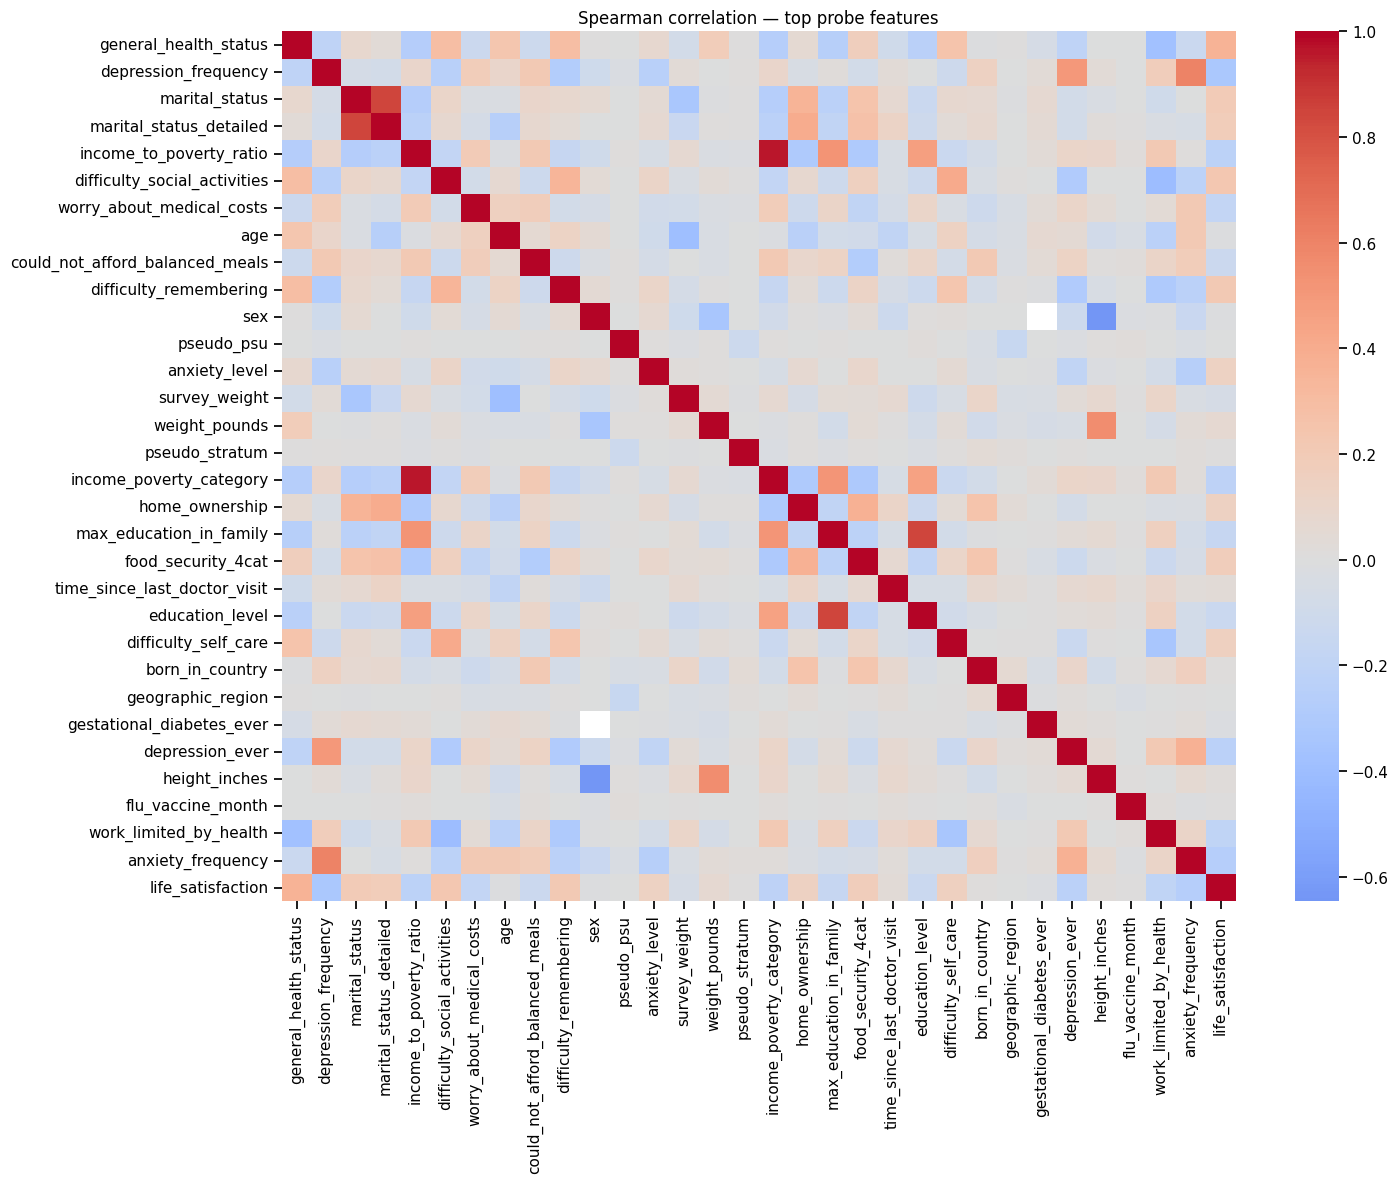

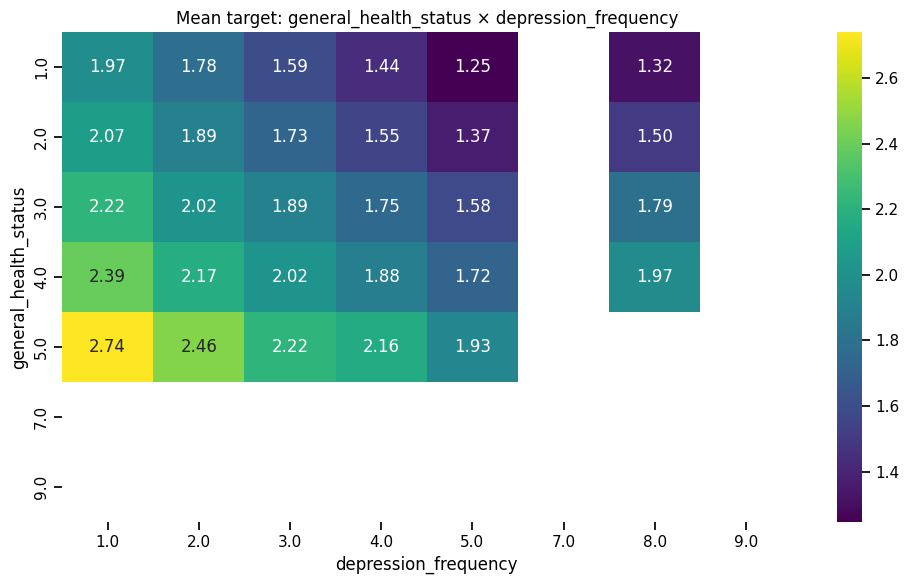

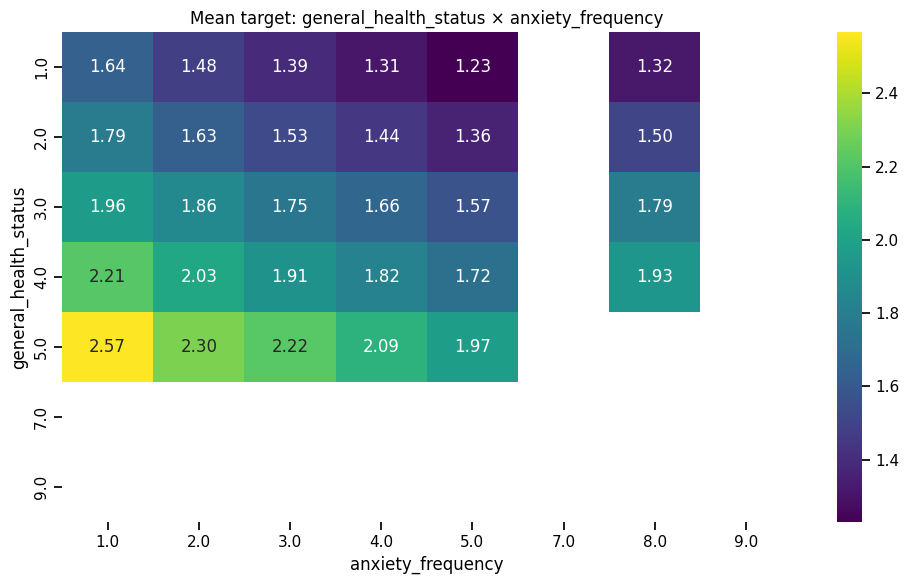

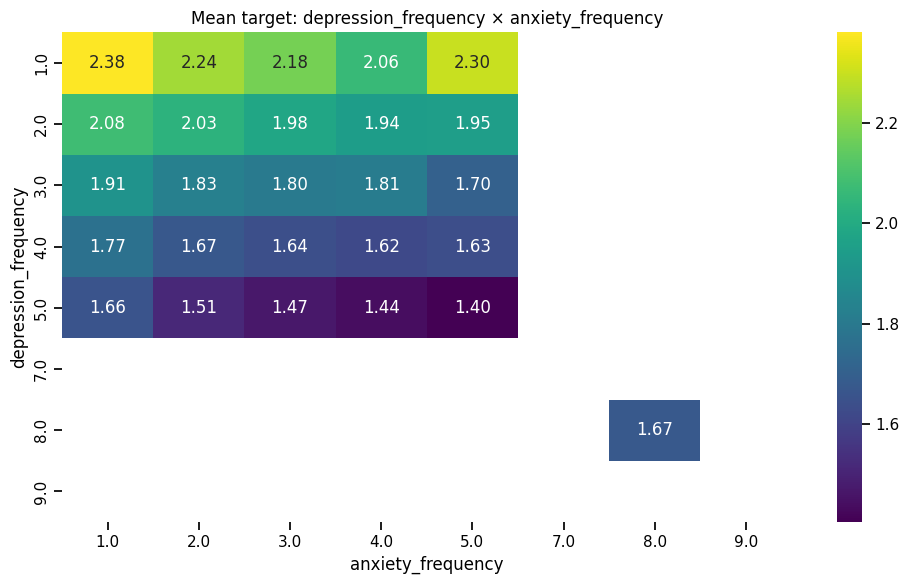

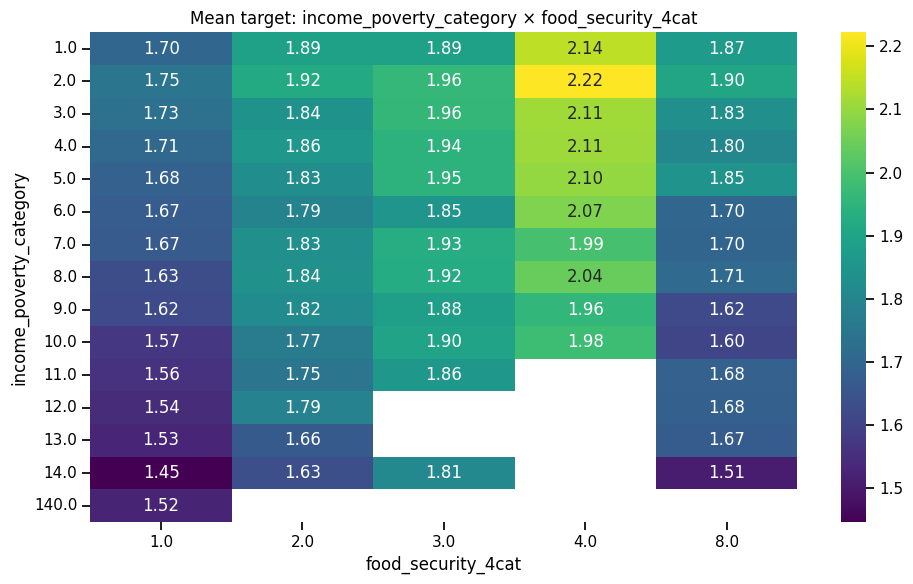

In [16]:
top_corr_features=[c for c in probe_imp.head(35).feature if c in train.columns]
if top_corr_features:
    corr=train[top_corr_features+[CFG.TARGET]].corr(method="spearman")
    plt.figure(figsize=(15,12)); sns.heatmap(corr,cmap="coolwarm",center=0); plt.title("Spearman correlation — top probe features"); plt.tight_layout(); plt.show()

def interaction_heatmap(df,a,b,min_count=80):
    if a not in df or b not in df: return
    z=df[[a,b,CFG.TARGET]].dropna()
    counts=z.pivot_table(index=a,columns=b,values=CFG.TARGET,aggfunc="size")
    means=z.pivot_table(index=a,columns=b,values=CFG.TARGET,aggfunc="mean").where(counts>=min_count)
    plt.figure(figsize=(10,6)); sns.heatmap(means,annot=True,fmt=".2f",cmap="viridis"); plt.title(f"Mean target: {a} × {b}"); plt.tight_layout(); plt.show()

for a,b in [
    ("general_health_status","depression_frequency"),
    ("general_health_status","anxiety_frequency"),
    ("depression_frequency","anxiety_frequency"),
    ("income_poverty_category","food_security_4cat"),
]: interaction_heatmap(train,a,b)


## 5. Feature Engineering


V3 explicitly follows the requested feature-engineering categories:

- **Discretization:** only conservative shortcuts such as `age_band`; raw values remain.
- **Feature selection:** fold-local LightGBM gain ranking with a hard total numeric budget of 175.
- **Feature creation:** burden counts, observed-code ontology, questionnaire path states/signatures, and fold-safe ordinal target encodings.
- **Clipping / outliers:** no global winsorization or row dropping. Survey special-response codes are modeled explicitly.
- **Feature encoding:** raw numeric code + categorical copy for CatBoost; smoothed OOF target/boundary encodings for LGB/XGB.

No StandardScaler, SMOTE, generic median fill, or blind class rebalancing is used.


### 5.1 Fold-safe categorical signal ranking and ordinal target encoding


In [17]:
def rank_categorical_candidates(X,y_arr,max_unique=120,top_n=36):
    tmp=X.copy(); tmp[CFG.TARGET]=y_arr
    sig=categorical_signal_table(tmp,max_unique=max_unique)
    # Reward both overall category association and category signal not captured by numeric order.
    sig["selection_score"]=sig["eta2"] + 0.55*sig["cat_minus_order"].clip(lower=0)
    return sig.sort_values("selection_score",ascending=False).head(top_n).feature.tolist(),sig

def smooth_map(values,target,global_mean,smooth=80.0):
    z=pd.DataFrame({"x":values,"y":target}).dropna()
    stat=z.groupby("x").y.agg(["mean","count"])
    stat["enc"]=(stat["mean"]*stat["count"]+global_mean*smooth)/(stat["count"]+smooth)
    return stat["enc"].to_dict()

def add_te_from_mapping(dest,source_col,mapping,default,name):
    dest[name]=source_col.map(mapping).fillna(default).astype(np.float32)

def make_oof_ordinal_te(Xtr,ytr,gtr,Xva,Xte,candidate_cols,extra_categorical=None,seed=42):
    tr_out=pd.DataFrame(index=Xtr.index); va_out=pd.DataFrame(index=Xva.index); te_out=pd.DataFrame(index=Xte.index)
    sources_tr={c:Xtr[c] for c in candidate_cols if c in Xtr}
    sources_va={c:Xva[c] for c in candidate_cols if c in Xva}
    sources_te={c:Xte[c] for c in candidate_cols if c in Xte}
    if extra_categorical:
        for name,(a,b,c) in extra_categorical.items():
            sources_tr[name]=a; sources_va[name]=b; sources_te[name]=c
    n=len(Xtr)
    strata_inner=pd.Series(ytr,index=Xtr.index).astype(str)
    cv_inner=StratifiedGroupKFold(n_splits=CFG.INNER_TE_FOLDS,shuffle=True,random_state=seed)
    inner=list(cv_inner.split(np.zeros(n),strata_inner,groups=gtr))
    targets={"mean":np.asarray(ytr,dtype=float),"gt1":(np.asarray(ytr)>1).astype(float),"gt2":(np.asarray(ytr)>2).astype(float),"gt3":(np.asarray(ytr)>3).astype(float)}
    for source_name,s_tr in sources_tr.items():
        s_va=sources_va[source_name]; s_te=sources_te[source_name]
        for suffix,targ in targets.items():
            default=float(np.mean(targ)); arr=np.full(n,default,dtype=np.float32)
            for itr,iva in inner:
                mp=smooth_map(s_tr.iloc[itr],targ[itr],float(np.mean(targ[itr])),CFG.TE_SMOOTH)
                arr[iva]=s_tr.iloc[iva].map(mp).fillna(float(np.mean(targ[itr]))).astype(float).values
            full_mp=smooth_map(s_tr,targ,default,CFG.TE_SMOOTH)
            col=f"TE__{source_name}__{suffix}"
            tr_out[col]=arr
            va_out[col]=s_va.map(full_mp).fillna(default).astype(np.float32).values
            te_out[col]=s_te.map(full_mp).fillna(default).astype(np.float32).values
    return tr_out,va_out,te_out


### 5.2 Build fold views


In [18]:
def numeric_feature_columns(df):
    return [c for c in df.columns if c not in {CFG.ID_COL,CFG.HOUSEHOLD_COL,CFG.TARGET} and pd.api.types.is_numeric_dtype(df[c])]

def build_base_views(raw_tr,raw_va,raw_te,fit_raw,enable_ontology=False,enable_paths=False):
    rules=learn_repair_rules(fit_raw)
    A=add_semantic_aggregates(apply_repair(raw_tr,rules))
    B=add_semantic_aggregates(apply_repair(raw_va,rules))
    C=add_semantic_aggregates(apply_repair(raw_te,rules))
    ontology=None; skip_rules=None; sigs=None
    if enable_ontology:
        ontology,_=infer_code_ontology(fit_raw)
        A=add_ontology_numeric(A,ontology); B=add_ontology_numeric(B,ontology); C=add_ontology_numeric(C,ontology)
    if enable_paths:
        skip_rules=learn_skip_rules(fit_raw)
        A=add_path_numeric(A,skip_rules); B=add_path_numeric(B,skip_rules); C=add_path_numeric(C,skip_rules)
        sigs=(make_path_signatures(A),make_path_signatures(B),make_path_signatures(C))
    return A,B,C,{"repair_rules":rules,"ontology":ontology,"skip_rules":skip_rules,"path_signatures":sigs}

def nested_gain_select(Xtr,ytr,gtr,candidates,budget=175,seed=42):
    candidates=[c for c in candidates if c in Xtr and pd.api.types.is_numeric_dtype(Xtr[c])]
    if len(candidates)<=budget: return candidates,pd.DataFrame({"feature":candidates,"gain":1.0})
    strata_inner=pd.Series(ytr,index=Xtr.index).astype(str)
    cv_inner=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=seed)
    itr,iva=next(cv_inner.split(Xtr,strata_inner,groups=gtr))
    m=lgb_regressor(seed,CFG.FS_ESTIMATORS)
    old_es=CFG.EARLY_STOPPING
    try:
        m.set_params(device_type="gpu")
        m.fit(Xtr.iloc[itr][candidates],np.asarray(ytr)[itr],eval_set=[(Xtr.iloc[iva][candidates],np.asarray(ytr)[iva])],callbacks=[lgb.early_stopping(CFG.FS_EARLY_STOPPING,verbose=False)])
    except Exception:
        m.set_params(device_type="cpu")
        m.fit(Xtr.iloc[itr][candidates],np.asarray(ytr)[itr],eval_set=[(Xtr.iloc[iva][candidates],np.asarray(ytr)[iva])],callbacks=[lgb.early_stopping(CFG.FS_EARLY_STOPPING,verbose=False)])
    imp=pd.DataFrame({"feature":candidates,"gain":m.booster_.feature_importance(importance_type="gain")}).sort_values("gain",ascending=False)
    return imp.head(budget).feature.tolist(),imp


## 6. Modeling


### 6.1 Cheap structural feature gate on one fixed fold


In [19]:
probe_tr,probe_va=folds[0]
raw_tr=train.iloc[probe_tr].drop(columns=[CFG.TARGET]).copy(); raw_va=train.iloc[probe_va].drop(columns=[CFG.TARGET]).copy(); raw_te=test.copy()
ytr=y[probe_tr]; yva=y[probe_va]; gtr=groups[probe_tr]

def score_probe_variant(name,Xtr,Xva,extra_te=None):
    feats=numeric_feature_columns(Xtr)
    m=lgb_regressor(100+len(PROBE_RESULTS),CFG.PROBE_ESTIMATORS)
    m=fit_lgb(m,Xtr[feats],ytr,Xva[feats],yva)
    p=m.predict(Xva[feats],num_iteration=m.best_iteration_)
    t,q=optimize_thresholds(yva,p)
    auc=boundary_auc(yva,p)["auc_gt1"]
    rmse=mean_squared_error(yva,p)**0.5
    PROBE_RESULTS.append({"variant":name,"qwk":q,"auc_gt1":auc,"rmse":rmse,"n_features":len(feats),"thresholds":t})
    return p

PROBE_RESULTS=[]
A0,B0,C0,meta0=build_base_views(raw_tr,raw_va,raw_te,raw_tr,False,False)
p0=score_probe_variant("base",A0,B0)

A1,B1,C1,meta1=build_base_views(raw_tr,raw_va,raw_te,raw_tr,True,False)
p1=score_probe_variant("ontology",A1,B1)

A2,B2,C2,meta2=build_base_views(raw_tr,raw_va,raw_te,raw_tr,False,True)
p2=score_probe_variant("paths",A2,B2)

# TE is evaluated on the clean base view; selection is learned from probe-tr only.
cat_candidates,probe_cat_sig=rank_categorical_candidates(raw_tr,ytr,CFG.CODE_MAX_UNIQUE,CFG.CAT_SIGNAL_TOP_N)
te_tr,te_va,te_te=make_oof_ordinal_te(A0,ytr,gtr,B0,C0,cat_candidates,seed=777)
A3=pd.concat([A0,te_tr],axis=1); B3=pd.concat([B0,te_va],axis=1); C3=pd.concat([C0,te_te],axis=1)
p3=score_probe_variant("ordinal_te",A3,B3)

# Combined structural view.
Ac,Bc,Cc,metac=build_base_views(raw_tr,raw_va,raw_te,raw_tr,True,True)
cat_candidates_c,_=rank_categorical_candidates(raw_tr,ytr,CFG.CODE_MAX_UNIQUE,CFG.CAT_SIGNAL_TOP_N)
path_extra=None
if metac["path_signatures"] is not None:
    st,sv,se=metac["path_signatures"]
    path_extra={c:(st[c],sv[c],se[c]) for c in st.columns}
tc_tr,tc_va,tc_te=make_oof_ordinal_te(Ac,ytr,gtr,Bc,Cc,cat_candidates_c,path_extra,seed=778)
Ac=pd.concat([Ac,tc_tr],axis=1); Bc=pd.concat([Bc,tc_va],axis=1); Cc=pd.concat([Cc,tc_te],axis=1)
pc=score_probe_variant("combined",Ac,Bc)

probe_df=pd.DataFrame(PROBE_RESULTS)
display(probe_df.drop(columns="thresholds").sort_values("qwk",ascending=False))
base=probe_df.set_index("variant").loc["base"]

def pass_gate(row):
    return (
        row.qwk-base.qwk >= CFG.PROBE_MIN_QWK_GAIN or
        row.auc_gt1-base.auc_gt1 >= CFG.PROBE_MIN_AUC_GAIN or
        base.rmse-row.rmse >= CFG.PROBE_MIN_RMSE_GAIN
    )

GATE={"ontology":pass_gate(probe_df.set_index("variant").loc["ontology"]),
      "paths":pass_gate(probe_df.set_index("variant").loc["paths"]),
      "ordinal_te":pass_gate(probe_df.set_index("variant").loc["ordinal_te"])}
combined_row=probe_df.set_index("variant").loc["combined"]
if combined_row.qwk-base.qwk >= 0.0010 or combined_row.auc_gt1-base.auc_gt1 >= 0.0012:
    # Synergy override: if the structural stack is clearly better together, retain all three blocks.
    GATE={k:True for k in GATE}
print("Structural gate:",GATE)


,variant,qwk,auc_gt1,rmse,n_features
3,ordinal_te,0.494476,0.780603,0.512972,331
0,base,0.493837,0.780719,0.513386,187
2,paths,0.493546,0.780570,0.513430,219
1,ontology,0.493252,0.780592,0.513049,508
4,combined,0.492201,0.779795,0.513384,720


Structural gate: {'ontology': np.False_, 'paths': np.False_, 'ordinal_te': np.True_}


### 6.2 CatBoost dual-view probe


In [20]:
def prepare_cat_view(Xnum,raw_source,cat_cols,path_sigs=None):
    out=Xnum.copy()
    cats=[]
    for c in cat_cols:
        if c not in raw_source: continue
        name=f"CAT__{c}"
        out[name]=raw_source[c].astype("object").where(raw_source[c].notna(),"__NA__").astype(str).values
        cats.append(name)
    if path_sigs is not None:
        for c in path_sigs.columns:
            out[f"CAT__{c}"]=path_sigs[c].astype(str).values
            cats.append(f"CAT__{c}")
    return out,cats

def cat_model(seed=42,iterations=None,use_gpu=None):
    if use_gpu is None: use_gpu=CFG.USE_GPU
    params=dict(
        loss_function="RMSE",iterations=iterations or CFG.CAT_ITERATIONS,learning_rate=CFG.LEARNING_RATE,depth=7,
        l2_leaf_reg=6.0,random_strength=0.5,random_seed=seed,verbose=False,allow_writing_files=False,
        task_type="GPU" if use_gpu else "CPU",
    )
    if use_gpu: params["devices"]=CFG.CAT_DEVICES
    else: params["thread_count"]=-1
    return CatBoostRegressor(**params)

# Use the best accepted structural numeric view for the probe.
P_tr,P_va,P_te,P_meta=build_base_views(raw_tr,raw_va,raw_te,raw_tr,GATE["ontology"],GATE["paths"])
cat_rank,_=rank_categorical_candidates(raw_tr,ytr,CFG.CODE_MAX_UNIQUE,CFG.CATBOOST_CAT_TOP_N)
path_sig_tr=path_sig_va=path_sig_te=None
if P_meta["path_signatures"] is not None:
    path_sig_tr,path_sig_va,path_sig_te=P_meta["path_signatures"]
num_probe=numeric_feature_columns(P_tr)
# Keep probe fast: top 150 by prior LGB gain if needed.
sel_probe, _ = nested_gain_select(P_tr,ytr,gtr,num_probe,min(150,CFG.FINAL_NUMERIC_BUDGET),seed=779)

cat_num=cat_model(779,1800)
try:
    cat_num.fit(P_tr[sel_probe],ytr,eval_set=(P_va[sel_probe],yva),early_stopping_rounds=120,verbose=False)
except Exception as e:
    print("CatBoost numeric probe GPU -> CPU fallback:",str(e)[:180])
    cat_num=cat_model(779,1800,use_gpu=False)
    cat_num.fit(P_tr[sel_probe],ytr,eval_set=(P_va[sel_probe],yva),early_stopping_rounds=120,verbose=False)
p_num=cat_num.predict(P_va[sel_probe])
t_num,q_num=optimize_thresholds(yva,p_num)

Ctr,cat_names=prepare_cat_view(P_tr[sel_probe],raw_tr,cat_rank,path_sig_tr)
Cva,_=prepare_cat_view(P_va[sel_probe],raw_va,cat_rank,path_sig_va)
cat_dual=cat_model(780,1800)
try:
    cat_dual.fit(Ctr,ytr,cat_features=cat_names,eval_set=(Cva,yva),early_stopping_rounds=120,verbose=False)
except Exception as e:
    print("CatBoost dual probe GPU -> CPU fallback:",str(e)[:180])
    cat_dual=cat_model(780,1800,use_gpu=False)
    cat_dual.fit(Ctr,ytr,cat_features=cat_names,eval_set=(Cva,yva),early_stopping_rounds=120,verbose=False)
p_dual=cat_dual.predict(Cva)
t_dual,q_dual=optimize_thresholds(yva,p_dual)
auc_num=boundary_auc(yva,p_num)["auc_gt1"]; auc_dual=boundary_auc(yva,p_dual)["auc_gt1"]
USE_CAT_DUAL=(q_dual-q_num>=0.0003) or (auc_dual-auc_num>=0.0005)
print({"cat_numeric_qwk":q_num,"cat_dual_qwk":q_dual,"cat_numeric_auc_gt1":auc_num,"cat_dual_auc_gt1":auc_dual,"USE_CAT_DUAL":USE_CAT_DUAL})
del cat_num,cat_dual,Ctr,Cva; gc.collect()


{'cat_numeric_qwk': np.float64(0.4921520108193095), 'cat_dual_qwk': np.float64(0.4946632293934837), 'cat_numeric_auc_gt1': np.float64(0.7810656106506575), 'cat_dual_auc_gt1': np.float64(0.7814221227820357), 'USE_CAT_DUAL': np.True_}


0

### 6.3 Final 5-fold structural portfolio


In [21]:
def xgb_regressor(seed=42,use_gpu=None):
    if use_gpu is None: use_gpu=CFG.USE_GPU
    params=dict(
        objective="reg:squarederror",n_estimators=CFG.XGB_N_ESTIMATORS,learning_rate=CFG.LEARNING_RATE,
        max_depth=6,min_child_weight=18,subsample=0.85,colsample_bytree=0.85,reg_alpha=0.10,reg_lambda=5.0,
        random_state=seed,n_jobs=-1,tree_method="hist",eval_metric="rmse",early_stopping_rounds=CFG.EARLY_STOPPING,
    )
    params["device"]="cuda" if use_gpu else "cpu"
    return xgb.XGBRegressor(**params)

model_names=["lgb_struct","xgb_struct","cat_dual" if USE_CAT_DUAL else "cat_numeric"]
oof={m:np.zeros(len(train),dtype=np.float32) for m in model_names}
test_pred={m:np.zeros(len(test),dtype=np.float64) for m in model_names}
feature_importance_rows=[]; fold_metric_rows=[]; selected_feature_rows=[]; cat_signal_rows=[]; skip_rule_rows=[]

for fold,(tr_idx,va_idx) in enumerate(folds):
    print("\n"+"="*80,"FOLD",fold,"="*80)
    raw_tr=train.iloc[tr_idx].drop(columns=[CFG.TARGET]).copy(); raw_va=train.iloc[va_idx].drop(columns=[CFG.TARGET]).copy(); raw_te=test.copy()
    ytr=y[tr_idx]; yva=y[va_idx]; gtr=groups[tr_idx]

    A,B,C,meta=build_base_views(raw_tr,raw_va,raw_te,raw_tr,GATE["ontology"],GATE["paths"])

    # Fold-safe category selection and TE.
    cat_candidates,cat_sig=rank_categorical_candidates(raw_tr,ytr,CFG.CODE_MAX_UNIQUE,CFG.CAT_SIGNAL_TOP_N)
    cat_sig=cat_sig.copy(); cat_sig["fold"]=fold; cat_signal_rows.append(cat_sig)
    path_extra=None
    if GATE["paths"] and meta["path_signatures"] is not None:
        st,sv,se=meta["path_signatures"]
        path_extra={c:(st[c],sv[c],se[c]) for c in st.columns}
    if GATE["ordinal_te"]:
        Ttr,Tva,Tte=make_oof_ordinal_te(A,ytr,gtr,B,C,cat_candidates,path_extra,seed=CFG.SEED+fold)
        A=pd.concat([A,Ttr],axis=1); B=pd.concat([B,Tva],axis=1); C=pd.concat([C,Tte],axis=1)

    numeric_candidates=numeric_feature_columns(A)
    selected,fs_imp=nested_gain_select(A,ytr,gtr,numeric_candidates,CFG.FINAL_NUMERIC_BUDGET,seed=CFG.SEED+100+fold)
    assert len(selected)<=CFG.FINAL_NUMERIC_BUDGET
    selected_feature_rows += [{"fold":fold,"feature":c,"rank":i+1} for i,c in enumerate(selected)]
    print("numeric candidates",len(numeric_candidates),"selected",len(selected),"TE",sum(c.startswith('TE__') for c in selected))

    # LightGBM
    ml=lgb_regressor(CFG.SEED+fold)
    ml=fit_lgb(ml,A[selected],ytr,B[selected],yva)
    pl=ml.predict(B[selected],num_iteration=ml.best_iteration_); ptl=ml.predict(C[selected],num_iteration=ml.best_iteration_)
    oof["lgb_struct"][va_idx]=pl; test_pred["lgb_struct"]+=ptl/CFG.N_FOLDS
    gains=ml.booster_.feature_importance(importance_type="gain")
    feature_importance_rows += [{"fold":fold,"model":"lgb_struct","feature":f,"importance":float(g)} for f,g in zip(selected,gains)]

    # XGBoost
    mx=xgb_regressor(CFG.SEED+fold)
    try:
        mx.fit(A[selected],ytr,eval_set=[(B[selected],yva)],verbose=False)
    except Exception as e:
        print("XGBoost CUDA -> CPU fallback:",str(e)[:180])
        mx=xgb_regressor(CFG.SEED+fold,use_gpu=False)
        mx.fit(A[selected],ytr,eval_set=[(B[selected],yva)],verbose=False)
    px=mx.predict(B[selected]); ptx=mx.predict(C[selected])
    oof["xgb_struct"][va_idx]=px; test_pred["xgb_struct"]+=ptx/CFG.N_FOLDS
    if hasattr(mx,"feature_importances_"):
        feature_importance_rows += [{"fold":fold,"model":"xgb_struct","feature":f,"importance":float(g)} for f,g in zip(selected,mx.feature_importances_)]

    # CatBoost: selected numeric view plus top raw categorical copies and questionnaire path signatures.
    cat_rank,_=rank_categorical_candidates(raw_tr,ytr,CFG.CODE_MAX_UNIQUE,CFG.CATBOOST_CAT_TOP_N)
    path_tr=path_va=path_te=None
    if GATE["paths"] and meta["path_signatures"] is not None:
        path_tr,path_va,path_te=meta["path_signatures"]
    if USE_CAT_DUAL:
        CA,cat_names=prepare_cat_view(A[selected],raw_tr,cat_rank,path_tr)
        CB,_=prepare_cat_view(B[selected],raw_va,cat_rank,path_va)
        CC,_=prepare_cat_view(C[selected],raw_te,cat_rank,path_te)
    else:
        CA,CB,CC=A[selected],B[selected],C[selected]; cat_names=[]
    mc=cat_model(CFG.SEED+fold)
    try:
        mc.fit(CA,ytr,cat_features=cat_names or None,eval_set=(CB,yva),early_stopping_rounds=CFG.EARLY_STOPPING,verbose=False)
    except Exception as e:
        print("CatBoost GPU -> CPU fallback:",str(e)[:180])
        mc=cat_model(CFG.SEED+fold,use_gpu=False)
        mc.fit(CA,ytr,cat_features=cat_names or None,eval_set=(CB,yva),early_stopping_rounds=CFG.EARLY_STOPPING,verbose=False)
    pc=mc.predict(CB); ptc=mc.predict(CC)
    cat_key=model_names[2]
    oof[cat_key][va_idx]=pc; test_pred[cat_key]+=ptc/CFG.N_FOLDS

    # Fold diagnostics using thresholds fitted on this fold only for diagnostics, not final cross-fit score.
    for name,p in [("lgb_struct",pl),("xgb_struct",px),(cat_key,pc)]:
        tt,qq=optimize_thresholds(yva,p)
        row={"fold":fold,"model":name,"qwk_local_threshold":qq,"rmse":mean_squared_error(yva,p)**0.5,"mae_cont":mean_absolute_error(yva,p)}
        row.update(boundary_auc(yva,p)); fold_metric_rows.append(row)
    if meta["skip_rules"]:
        skip_rule_rows += [{"fold":fold,**{k:(sorted(v) if isinstance(v,set) else v) for k,v in r.items()}} for r in meta["skip_rules"]]

    del A,B,C,CA,CB,CC,ml,mx,mc; gc.collect()

display(pd.DataFrame(fold_metric_rows))



================================================================================ FOLD 0 ================================================================================
numeric candidates 331 selected 175 TE 96

================================================================================ FOLD 1 ================================================================================
numeric candidates 331 selected 175 TE 100

================================================================================ FOLD 2 ================================================================================
numeric candidates 331 selected 175 TE 97

================================================================================ FOLD 3 ================================================================================
numeric candidates 331 selected 175 TE 97

================================================================================ FOLD 4 ==============================================================

,fold,model,qwk_local_threshold,rmse,mae_cont,auc_gt1,auc_gt2,auc_gt3
0,0,lgb_struct,0.492049,0.513114,0.427620,0.780255,0.882932,0.834612
1,0,xgb_struct,0.492585,0.512999,0.427313,0.780440,0.882348,0.834468
2,0,cat_dual,0.495191,0.512337,0.426970,0.781997,0.883454,0.835328
3,1,lgb_struct,0.480000,0.515713,0.428067,0.778176,0.862595,0.785409
4,1,xgb_struct,0.481506,0.515508,0.426189,0.779172,0.861885,0.786084
5,1,cat_dual,0.477833,0.515334,0.426940,0.779673,0.863139,0.786964
6,2,lgb_struct,0.478842,0.520190,0.429164,0.775336,0.872727,0.799963
7,2,xgb_struct,0.478752,0.520301,0.429150,0.774956,0.873757,0.801297
8,2,cat_dual,0.479421,0.519460,0.428834,0.776256,0.873070,0.801561
9,3,lgb_struct,0.469668,0.516958,0.428818,0.776313,0.866972,0.788906


## 7. Evaluation


### 7.1 Individual model diagnostics, residual diversity, and equal blend


In [22]:
oof_mat=np.column_stack([oof[m] for m in model_names])
test_mat=np.column_stack([test_pred[m] for m in model_names])
individual=[]
for j,m in enumerate(model_names):
    t0,q0=optimize_thresholds(y,oof_mat[:,j])
    row={"model":m,"global_qwk":q0,"rmse":mean_squared_error(y,oof_mat[:,j])**0.5}
    row.update(boundary_auc(y,oof_mat[:,j])); individual.append(row)
display(pd.DataFrame(individual).sort_values("global_qwk",ascending=False))

resid=np.column_stack([y-oof_mat[:,j] for j in range(oof_mat.shape[1])])
print("Prediction correlation")
display(pd.DataFrame(np.corrcoef(oof_mat,rowvar=False),index=model_names,columns=model_names))
print("Residual correlation")
display(pd.DataFrame(np.corrcoef(resid,rowvar=False),index=model_names,columns=model_names))

equal_oof=oof_mat.mean(axis=1); equal_test=test_mat.mean(axis=1)
t_eq,q_eq=optimize_thresholds(y,equal_oof)
print("Equal blend global QWK",q_eq,"thresholds",np.round(t_eq,5),boundary_auc(y,equal_oof))


,model,global_qwk,rmse,auc_gt1,auc_gt2,auc_gt3
1,xgb_struct,0.479622,0.516419,0.778208,0.871876,0.808707
0,lgb_struct,0.479369,0.516296,0.778225,0.872216,0.808442
2,cat_dual,0.479244,0.515727,0.779263,0.872561,0.810046


Prediction correlation


,lgb_struct,xgb_struct,cat_dual
lgb_struct,1.000000,0.993838,0.990773
xgb_struct,0.993838,1.000000,0.990098
cat_dual,0.990773,0.990098,1.000000


Residual correlation


,lgb_struct,xgb_struct,cat_dual
lgb_struct,1.000000,0.997600,0.996421
xgb_struct,0.997600,1.000000,0.996139
cat_dual,0.996421,0.996139,1.000000


Equal blend global QWK 0.48121124850370334 thresholds [1.54624 2.00945 2.52496] {'auc_gt1': np.float64(0.7792810254181965), 'auc_gt2': np.float64(0.872969882603635), 'auc_gt3': np.float64(0.8095721425143793)}


### 7.2 Cross-fitted weight + threshold selection


In [23]:
def dirichlet_candidates(n_models,n=50,seed=42):
    rng=np.random.default_rng(seed)
    arr=[np.ones(n_models)/n_models]
    arr += [np.eye(n_models)[i] for i in range(n_models)]
    arr += list(rng.dirichlet(np.ones(n_models)*2.0,size=n))
    return np.asarray(arr)

cands=dirichlet_candidates(len(model_names),CFG.BLEND_RANDOM_CANDIDATES,42)
cf_pred=np.zeros(len(train),dtype=int)
cf_cont=np.zeros(len(train),dtype=float)
weight_rows=[]
for f,(_,va_idx) in enumerate(folds):
    trmask=fold_id!=f
    best=None
    for w in cands:
        s=oof_mat[trmask]@w
        t,q=optimize_thresholds(y[trmask],s)
        if best is None or q>best[0]: best=(q,w.copy(),t.copy())
    qtrain,w,t=best
    cf_cont[va_idx]=oof_mat[va_idx]@w
    cf_pred[va_idx]=apply_thresholds(cf_cont[va_idx],t)
    weight_rows.append({"fold":f,"train_qwk":qtrain,"weights":w,"thresholds":t})

weighted_cf_qwk=qwk(y,cf_pred)
# Equal blend cross-fitted thresholds for an apples-to-apples guardrail.
eq_cf=np.zeros(len(train),dtype=int)
for f,(_,va_idx) in enumerate(folds):
    trmask=fold_id!=f
    t,_=optimize_thresholds(y[trmask],equal_oof[trmask])
    eq_cf[va_idx]=apply_thresholds(equal_oof[va_idx],t)
eq_cf_qwk=qwk(y,eq_cf)

weights_df=pd.DataFrame([{"fold":r["fold"],**{model_names[j]:r["weights"][j] for j in range(len(model_names))}} for r in weight_rows])
display(weights_df)
print("equal cross-fit QWK",eq_cf_qwk)
print("weighted cross-fit QWK",weighted_cf_qwk,"gain",weighted_cf_qwk-eq_cf_qwk)

USE_WEIGHTED = weighted_cf_qwk-eq_cf_qwk >= CFG.MIN_WEIGHTED_BLEND_GAIN
final_weights=weights_df[model_names].mean().values if USE_WEIGHTED else np.ones(len(model_names))/len(model_names)
final_weights=final_weights/final_weights.sum()
print("USE_WEIGHTED",USE_WEIGHTED,"final weights",dict(zip(model_names,np.round(final_weights,4))))
final_oof=oof_mat@final_weights
final_test_raw=test_mat@final_weights
final_thresholds,final_global_qwk=optimize_thresholds(y,final_oof)


,fold,lgb_struct,xgb_struct,cat_dual
0,0,0.522118,0.435520,0.042362
1,1,0.552648,0.322693,0.124659
2,2,0.552648,0.322693,0.124659
3,3,0.224618,0.592375,0.183007
4,4,0.402100,0.255402,0.342498


equal cross-fit QWK 0.4799484891517266
weighted cross-fit QWK 0.47944200156077643 gain -0.0005064875909501776
USE_WEIGHTED False final weights {'lgb_struct': np.float64(0.3333), 'xgb_struct': np.float64(0.3333), 'cat_dual': np.float64(0.3333)}


### 7.3 Honest cross-fitted QWK, unique-ID OOF, and boundary checks


In [24]:
# Cross-fitted thresholds for the chosen fixed final weights.
final_cf_pred=np.zeros(len(train),dtype=int)
for f,(_,va_idx) in enumerate(folds):
    trmask=fold_id!=f
    t,_=optimize_thresholds(y[trmask],final_oof[trmask])
    final_cf_pred[va_idx]=apply_thresholds(final_oof[va_idx],t)
final_crossfit_qwk=qwk(y,final_cf_pred)

# Evaluator contract is one row per unique ID. Train duplicate IDs are exact label duplicates, so evaluate that view too.
oof_unique=pd.DataFrame({CFG.ID_COL:train[CFG.ID_COL].values,"y":y,"score":final_oof})
oof_unique=oof_unique.groupby(CFG.ID_COL,sort=False,as_index=False).agg(y=("y","first"),score=("score","mean"))
ut,uq=optimize_thresholds(oof_unique.y.values,oof_unique.score.values)

metrics={
    "v1_public_lb":CFG.V1_PUBLIC_LB,
    "v2_public_lb":CFG.V2_PUBLIC_LB,
    "v2_crossfit_oof_reference":CFG.V2_CROSSFIT_OOF,
    "final_global_qwk":final_global_qwk,
    "final_crossfit_qwk":final_crossfit_qwk,
    "final_unique_id_qwk":uq,
    "rmse":mean_squared_error(y,final_oof)**0.5,
    "mae_cont":mean_absolute_error(y,final_oof),
    **boundary_auc(y,final_oof),
}
display(pd.Series(metrics,name="value").to_frame())
print("Final thresholds",np.round(final_thresholds,6))

# Important: V2's main bottleneck was y>1 AUC ~0.780. A true structural gain should ideally improve latent ranking, not only QWK marginals.


,value
v1_public_lb,0.480030
v2_public_lb,0.481930
v2_crossfit_oof_reference,0.481367
final_global_qwk,0.481211
final_crossfit_qwk,0.479948
final_unique_id_qwk,0.480846
rmse,0.515582
mae_cont,0.427304
auc_gt1,0.779281
auc_gt2,0.872970


Final thresholds [1.546244 2.009455 2.524963]


### 7.4 Residual EDA: what V3 still misses


In [25]:
residual=y-final_oof
res_rows=[]
for c in cat_signal_full.head(50).feature:
    if c not in train: continue
    z=pd.DataFrame({"x":train[c],"res":residual,"y":y}).dropna()
    if z.empty: continue
    stats=z.groupby("x").agg(n=("res","size"),resid_mean=("res","mean"),target_mean=("y","mean"))
    stats=stats[stats.n>=100]
    if len(stats):
        worst=stats.iloc[np.argmax(np.abs(stats.resid_mean.values))]
        res_rows.append({"feature":c,"max_abs_resid_bias":float(abs(worst.resid_mean)),"state":stats.index[np.argmax(np.abs(stats.resid_mean.values))],"n":int(worst.n)})
residual_audit=pd.DataFrame(res_rows).sort_values("max_abs_resid_bias",ascending=False)
display(residual_audit.head(35))


,feature,max_abs_resid_bias,state,n
30,difficulty_seeing,0.081822,4.0,124
22,food_did_not_last,0.080948,7.0,113
17,could_not_afford_balanced_meals,0.080284,7.0,116
35,education_level,0.079050,97.0,122
34,trouble_paying_medical_bills,0.079047,9.0,132
40,low_income_government_insurance,0.076554,2.0,120
18,worried_food_would_run_out,0.066058,7.0,108
41,received_food_assistance,0.055131,7.0,339
2,anxiety_frequency,0.049494,7.0,110
28,difficulty_using_hands,0.048497,4.0,267


### 7.5 OOF ↔ test distribution sanity check


In [26]:
print("Continuous KS OOF vs raw test:",ks_2samp(final_oof,final_test_raw).statistic)
print(pd.DataFrame({
    "OOF":pd.Series(final_oof).quantile([.01,.1,.25,.5,.75,.9,.99]),
    "TEST":pd.Series(final_test_raw).quantile([.01,.1,.25,.5,.75,.9,.99]),
}))


Continuous KS OOF vs raw test: 0.010402614288338607
           OOF      TEST
0.01  1.078674  1.077723
0.10  1.232104  1.233997
0.25  1.370796  1.377440
0.50  1.567290  1.573445
0.75  1.785279  1.786613
0.90  2.017696  2.020246
0.99  2.603709  2.614575


### 7.6 Correct submission: aggregate continuous prediction by unique test ID, then threshold


In [27]:
# IMPORTANT: Kaggle evaluator expects 23,666 rows, one per unique test_final.id.
# Aggregate CONTINUOUS predictions first. Only then discretize.
submission_work=pd.DataFrame({CFG.ID_COL:test[CFG.ID_COL].values,"score":final_test_raw})
submission_work=(submission_work.groupby(CFG.ID_COL,sort=False,as_index=False)["score"].mean())
submission_work[CFG.TARGET]=apply_thresholds(submission_work["score"].values,final_thresholds).astype(int)
submission=submission_work[[CFG.ID_COL,CFG.TARGET]].copy()

assert len(submission)==CFG.EXPECTED_UNIQUE_TEST_IDS, len(submission)
assert submission[CFG.ID_COL].is_unique
assert submission[CFG.TARGET].notna().all()
assert set(submission[CFG.TARGET].unique()).issubset({1,2,3,4})
# Preserve first-appearance unique ID order from test_final.
expected_order=pd.Index(test[CFG.ID_COL].drop_duplicates().values)
assert np.array_equal(submission[CFG.ID_COL].values,expected_order.values)

submission_path=CFG.OUTPUT_DIR/"submission_v3.csv"
submission.to_csv(submission_path,index=False)
print("Saved",submission_path,"rows",len(submission))
display(submission[CFG.TARGET].value_counts().sort_index().to_frame("count"))


Saved /kaggle/working/oqdq5_v3/submission_v3.csv rows 23666


,count
life_satisfaction,
1,11010
2,10187
3,2126
4,343


### 7.7 Last-slot decision rule and artifacts


**V3 fixed note:** JSON artifact serialization now normalizes NumPy scalar types (`np.bool_`, `np.integer`, `np.floating`) before `json.dump`, fixing the Kaggle end-of-run failure seen after the submission CSV had already been written.


In [28]:
# V1/V2 leaderboard transfer was almost 1:1, so require a meaningful internal move.
# This is diagnostic, not a hard blocker: the file is always written so the team can decide.
worth_last_slot = (
    final_crossfit_qwk >= 0.486 or
    (final_crossfit_qwk >= 0.484 and metrics["auc_gt1"] >= 0.785)
)
print("WORTH_LAST_SLOT =",worth_last_slot)
if worth_last_slot:
    print("V3 shows a materially stronger internal signal than V2. submission_v3.csv is a justified last-slot candidate.")
else:
    print("V3 did not clear the predeclared breakthrough gate. Treat submission_v3.csv as exploratory rather than a confident Top-1 attack.")

# Save diagnostics for the next iteration.
oof_df=pd.DataFrame({CFG.ID_COL:train[CFG.ID_COL],"fold":fold_id,"target":y,"final_score":final_oof,"final_pred_cf":final_cf_pred})
for m in model_names: oof_df[m]=oof[m]
test_pred_df=pd.DataFrame({CFG.ID_COL:test[CFG.ID_COL],"final_score":final_test_raw})
for m in model_names: test_pred_df[m]=test_pred[m]

artifacts={
    "oof":CFG.OUTPUT_DIR/"oof_v3.csv",
    "test_predictions":CFG.OUTPUT_DIR/"test_predictions_v3.csv",
    "fold_metrics":CFG.OUTPUT_DIR/"fold_metrics_v3.csv",
    "feature_selection":CFG.OUTPUT_DIR/"feature_selection_v3.csv",
    "feature_importance":CFG.OUTPUT_DIR/"feature_importance_v3.csv",
    "categorical_signal":CFG.OUTPUT_DIR/"categorical_signal_v3.csv",
    "skip_rules":CFG.OUTPUT_DIR/"skip_rules_v3.csv",
    "probe":CFG.OUTPUT_DIR/"structural_probe_v3.csv",
    "residual_audit":CFG.OUTPUT_DIR/"residual_audit_v3.csv",
    "summary":CFG.OUTPUT_DIR/"v3_summary.json",
}

oof_df.to_csv(artifacts["oof"],index=False)
test_pred_df.to_csv(artifacts["test_predictions"],index=False)
pd.DataFrame(fold_metric_rows).to_csv(artifacts["fold_metrics"],index=False)
pd.DataFrame(selected_feature_rows).to_csv(artifacts["feature_selection"],index=False)
pd.DataFrame(feature_importance_rows).to_csv(artifacts["feature_importance"],index=False)
pd.concat(cat_signal_rows,ignore_index=True).to_csv(artifacts["categorical_signal"],index=False)
pd.DataFrame(skip_rule_rows).to_csv(artifacts["skip_rules"],index=False)
probe_df.drop(columns="thresholds").to_csv(artifacts["probe"],index=False)
residual_audit.to_csv(artifacts["residual_audit"],index=False)

summary={
    "version":"v3","competition":CFG.COMPETITION_NAME,
    "v1_public_lb_reference":CFG.V1_PUBLIC_LB,"v2_public_lb_reference":CFG.V2_PUBLIC_LB,"current_top1_reference":CFG.CURRENT_TOP1_PUBLIC,
    "structural_gate":GATE,"use_cat_dual":bool(USE_CAT_DUAL),"model_names":model_names,
    "equal_crossfit_qwk":float(eq_cf_qwk),"weighted_crossfit_qwk":float(weighted_cf_qwk),"use_weighted":bool(USE_WEIGHTED),
    "final_weights":{m:float(w) for m,w in zip(model_names,final_weights)},
    "final_global_qwk":float(final_global_qwk),"final_crossfit_qwk":float(final_crossfit_qwk),"final_unique_id_qwk":float(uq),
    "final_thresholds":[float(x) for x in final_thresholds],"auc_gt1":float(metrics["auc_gt1"]),"auc_gt2":float(metrics["auc_gt2"]),"auc_gt3":float(metrics["auc_gt3"]),
    "submission_rows":int(len(submission)),"worth_last_slot":bool(worth_last_slot),
    "notes":[
        "Observed-code ontology learned from raw fold data, not dictionary-valid-code truncation",
        "Questionnaire skip/applicability states learned without target inside each fold",
        "Fold-safe ordinal target encodings for high-signal coded categories",
        "CatBoost dual numeric+categorical view gated by a cheap probe",
        "Hard numeric feature budget <=175",
        "Single 5-fold grouped CV; no repeated-CV sidecar explosion",
        "Submission aggregated to 23,666 unique test_final.id rows before thresholding",
    ]
}
def _json_default(obj):
    """Final fallback for NumPy/Pandas/Path objects that stdlib json cannot encode."""
    if isinstance(obj, np.generic):
        return obj.item()
    if isinstance(obj, Path):
        return str(obj)
    if hasattr(obj, "to_pydatetime"):
        try:
            return obj.to_pydatetime().isoformat()
        except Exception:
            pass
    if hasattr(obj, "tolist"):
        try:
            return obj.tolist()
        except Exception:
            pass
    if hasattr(obj, "item"):
        try:
            return obj.item()
        except Exception:
            pass
    return str(obj)

def _json_safe(obj):
    """Recursively normalize containers before serialization."""
    if isinstance(obj, dict):
        return {str(_json_safe(k)): _json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_json_safe(v) for v in obj]
    if isinstance(obj, np.generic):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    if hasattr(obj, "to_pydatetime"):
        try:
            return obj.to_pydatetime().isoformat()
        except Exception:
            pass
    if hasattr(obj, "item") and not isinstance(obj, (str, bytes)):
        try:
            return obj.item()
        except Exception:
            pass
    return obj

summary = _json_safe(summary)

# Validate in-memory before touching disk. default= is intentionally kept as a
# second safety net even after recursive normalization.
json.dumps(summary, indent=2, default=_json_default)

with open(artifacts["summary"], "w") as f:
    json.dump(summary, f, indent=2, default=_json_default)

print("Artifacts:")
print(" -",submission_path)
for p in artifacts.values(): print(" -",p)
display(pd.Series(summary).to_frame("value"))


WORTH_LAST_SLOT = False
V3 did not clear the predeclared breakthrough gate. Treat submission_v3.csv as exploratory rather than a confident Top-1 attack.
Artifacts:
 - /kaggle/working/oqdq5_v3/submission_v3.csv
 - /kaggle/working/oqdq5_v3/oof_v3.csv
 - /kaggle/working/oqdq5_v3/test_predictions_v3.csv
 - /kaggle/working/oqdq5_v3/fold_metrics_v3.csv
 - /kaggle/working/oqdq5_v3/feature_selection_v3.csv
 - /kaggle/working/oqdq5_v3/feature_importance_v3.csv
 - /kaggle/working/oqdq5_v3/categorical_signal_v3.csv
 - /kaggle/working/oqdq5_v3/skip_rules_v3.csv
 - /kaggle/working/oqdq5_v3/structural_probe_v3.csv
 - /kaggle/working/oqdq5_v3/residual_audit_v3.csv
 - /kaggle/working/oqdq5_v3/v3_summary.json


,value
version,v3
competition,Objective Quest DATAQUEST 5.0
v1_public_lb_reference,0.48003
v2_public_lb_reference,0.48193
current_top1_reference,0.61541
structural_gate,"{'ontology': False, 'paths': False, 'ordinal_t..."
use_cat_dual,True
model_names,"[lgb_struct, xgb_struct, cat_dual]"
equal_crossfit_qwk,0.479948
weighted_crossfit_qwk,0.479442


## V3 Interpretation Guide

Use **cross-fitted QWK and `AUC(y>1)` together**. V2 improved QWK while barely improving latent ranking; V3 is intended to find actual structural signal.

- `final_crossfit_qwk < 0.483`: structural representation did not solve the ceiling; do not spend more time tuning this exact architecture.
- `0.483–0.486`: genuine progress, but still incremental relative to the 0.61541 leader.
- `>= 0.486` with `AUC(y>1) > ~0.785`: strong enough to justify the last daily submission.
- `>= 0.490`: clear breakthrough relative to V1/V2 and a very informative leaderboard attack.

The most important diagnostics are:

1. Which structural blocks passed the cheap gate.
2. Whether CatBoost dual-view beat numeric CatBoost on the probe.
3. Whether residual correlations between the three final models are materially below V1/V2's ~0.99+ regime.
4. Whether `AUC(y>1)` improves, since class 1↔2 dominated V1/V2's QWK disagreement.
5. Whether OOF and test score distributions remain aligned.
6. Submission must contain **exactly 23,666 unique IDs**.
